# UTS Graf Sains Data — Neo4j + Rekomendasi (RetailRocket)
**Nama / NIM:** _Maria Agatha Metri Tetrajati / 24031554189_ |  **Periode P1 (train):** _"2015-06-01" - "2015-06-15"_ |  **Periode P2 (test):** _"2015-08-16" - "2015-08-31"_


## 0. Persiapan
Terminal (di luar notebook):
```
uv venv myvenv --python 3.10
source myvenv/bin/activate 
uv pip install "neo4j>=5.20" pandas numpy scipy scikit-learn networkx matplotlib tqdm jupyter
```

Unduh dataset (Linux/Mac): `curl -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset`

In [1]:
import os, zipfile
import numpy as np, pandas as pd
from scipy import sparse
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase
from neo4j import RoutingControl

URI  = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "******")
DB   = "neo4j"
DATA_DIR = "data"

P1 = ("2015-06-01", "2015-06-15")   #training
P2 = ("2015-08-16", "2015-08-31")   #testing

MIN_INTERACTIONS = 5
MAX_USERS = 20000
SEED = 42
BATCH_SIZE = 5000
WEIGHT = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}

os.makedirs(DATA_DIR, exist_ok=True)
if os.path.exists("ecommerce-dataset.zip") and not os.path.exists(f"{DATA_DIR}/events.csv"):
    with zipfile.ZipFile("ecommerce-dataset.zip") as z:
        z.extractall(DATA_DIR)
print(os.listdir(DATA_DIR))

['item_properties_part1.csv', 'item_properties_part2.csv', 'events_P1_train.csv', 'category_tree.csv', 'events_P2_test.csv', 'events.csv']


In [2]:
driver = GraphDatabase.driver("bolt://127.0.0.1:7687", auth=("neo4j", "******"))
driver.verify_connectivity()
print("Terhubung!")

Terhubung!


In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


1. Nama database yang dipakai?
neo4j, terlihat dari parameter database_="neo4j". Itu database default pada instance Neo4j.

2. Akses lain ke database lain dalam 1 instance?
Ada beberapa cara, tergantung versi Neo4j:

SHOW DATABASES untuk melihat daftar database.
CREATE DATABASE namadb untuk membuat database baru.Pada edisi Community hanya tersedia satu database user dan satu database system, sedangkan CREATE DATABASE hanya di edisi Enterprise.
:use namadb di Neo4j Browser atau cypher-shell, atau klausa USE namadb di awal query, untuk mengarahkan query ke database tertentu.
Di Python, lewat parameter database_="namadb" pada execute_query atau driver.session(database="namadb"). Contohnya di tugas 1.3 yang memakai database="system".

3. Jenis graf pertemanan yang dibuat?
Graf berarah (directed) dengan relasi KNOWS dari Person ke Person. Arthur → Guinevere, Lancelot, dan Merlin, sehingga Arthur menjadi pusat (out-degree 3). Grafnya juga:

tidak berbobot, karena relasi tidak punya properti bobot,
satu jenis simpul (Person) dan satu jenis relasi (KNOWS),
tidak simetris: Arthur “kenal” Guinevere, tapi sebaliknya tidak ada. Karena itu MATCH (a)-[:KNOWS]->(friend) hanya mengembalikan teman Arthur, bukan sebaliknya.
bebas duplikat karena memakai MERGE. Menjalankan add_friend dua kali tidak membuat simpul atau relasi ganda.

## 2.1 Wrangling dan EDA

### No. 1 — Tentukan 2 periode waktu
`timestamp` pada RetailRocket berformat **unix epoch milidetik**, jadi dikonversi dengan `unit="ms"`.

In [4]:
ev = pd.read_csv(f"{DATA_DIR}/events.csv")
ev["ts"] = pd.to_datetime(ev["timestamp"], unit="ms")
print(ev.shape); print(ev.dtypes, "\n")
print("Rentang waktu:", ev["ts"].min(), "->", ev["ts"].max(), "\n")
print(ev["event"].value_counts(), "\n")
print("visitor unik:", ev["visitorid"].nunique(), "| item unik:", ev["itemid"].nunique())
print(ev.isna().sum())

(2756101, 6)
timestamp                 int64
visitorid                 int64
event                       str
itemid                    int64
transactionid           float64
ts               datetime64[ms]
dtype: object 

Rentang waktu: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000 

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64 

visitor unik: 1407580 | item unik: 235061
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
ts                     0
dtype: int64


### No. 2 — Terapkan filter pada timestamp, simpan ke .csv
potong data per periode → ambil user yang aktif di P1 (≥ `MIN_INTERACTIONS`) **dan** muncul di P2 (supaya evaluasi Hit@5/NDCG@5 punya *ground truth*) → sampling reproducible → simpan.

In [5]:
def cut(df, period):
    start = pd.Timestamp(period[0]); end = pd.Timestamp(period[1]) + pd.Timedelta(days=1)
    return df[(df["ts"] >= start) & (df["ts"] < end)]

p1, p2 = cut(ev, P1), cut(ev, P2)
c1, c2 = p1.groupby("visitorid").size(), p2.groupby("visitorid").size()
cand = np.sort(c1[c1 >= MIN_INTERACTIONS].index.intersection(c2.index).values)
rng = np.random.default_rng(SEED)
keep = rng.choice(cand, size=min(MAX_USERS, len(cand)), replace=False)

p1 = p1[p1["visitorid"].isin(keep)].drop(columns="ts")
p2 = p2[p2["visitorid"].isin(keep)].drop(columns="ts")
p1.to_csv(f"{DATA_DIR}/events_P1_train.csv", index=False)
p2.to_csv(f"{DATA_DIR}/events_P2_test.csv", index=False)
print("kandidat user:", len(cand), "| dipakai:", len(keep))
print("P1 (train):", p1.shape, "| P2 (test):", p2.shape)

kandidat user: 320 | dipakai: 320
P1 (train): (6570, 5) | P2 (test): (5538, 5)


### No. 3 — Impor ke Neo4j & komposisi subgraph
Hanya **P1 (train)** yang masuk ke graf; P2 dipakai sebagai kunci jawaban evaluasi.
Model graf: `(:Visitor)-[:VIEWED | :ADDED_TO_CART | :BOUGHT]->(:Item)`.

In [6]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def run(q, **params):
    recs, _, _ = driver.execute_query(q, parameters_=params, database_=DB)
    return pd.DataFrame([r.data() for r in recs])

TEMPLATE = """UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:%s {timestamp: row.timestamp%s}]->(i)"""
QUERY = {
    "view":        TEMPLATE % ("VIEWED", ""),
    "addtocart":   TEMPLATE % ("ADDED_TO_CART", ""),
    "transaction": TEMPLATE % ("BOUGHT", ", transactionId: row.transactionid"),
}

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_csv(path):
    with open(path) as f: total = sum(1 for _ in f) - 1
    with driver.session(database=DB) as session:
        create_constraints(session)
        for chunk in tqdm(pd.read_csv(path, chunksize=BATCH_SIZE), total=total // BATCH_SIZE + 1, desc="Impor batch"):
            for ev_type, q in QUERY.items():
                sub = chunk[chunk["event"] == ev_type]
                if sub.empty: continue
                if ev_type == "transaction":
                    sub = sub.assign(transactionid=sub["transactionid"].astype("int64"))
                else:
                    sub = sub.drop(columns=["transactionid"])
                records = sub.to_dict(orient="records")
                session.execute_write(lambda tx, q=q, r=records: tx.run(q, batch=r).consume())

# bersihkan graf lama
run("MATCH (n) DETACH DELETE n")
import_csv(f"{DATA_DIR}/events_P1_train.csv")

Impor batch:   0%|          | 0/2 [00:00<?, ?it/s]

In [7]:
# Komposisi subgraph: jenis simpul & jumlahnya
nodes = run("MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah ORDER BY jumlah DESC")
rels  = run("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah ORDER BY jumlah DESC")
display(nodes); display(rels)

,jenis_simpul,jumlah
0,Item,3430
1,Visitor,320


,jenis_relasi,jumlah
0,VIEWED,6194
1,ADDED_TO_CART,276
2,BOUGHT,100


**No. 3 — Uraian jenis simpul dan jumlah masing-masing simpul**

Query dijalankan lewat Python API Neo4j (`driver.execute_query`) pada fungsi `run()`, lalu hasilnya dikembalikan sebagai DataFrame pandas.

| Jenis simpul | Jumlah |
|---|---|
| Item | 3.430 |
| Visitor | 320 |
| **Total simpul** | **3.750** |

| Jenis relasi | Jumlah |
|---|---|
| VIEWED | 6.194 |
| ADDED_TO_CART | 276 |
| BOUGHT | 100 |
| **Total relasi** | **6.570** |

Subgraph ini hanya punya dua jenis simpul, yaitu `Visitor` (pengunjung) dan `Item` (produk), serta tiga jenis relasi yang selalu berarah dari `Visitor` ke `Item`. Jadi bentuknya graf bipartit: tidak ada relasi antar-Visitor maupun antar-Item. Jumlah relasi (6.570) sama dengan jumlah baris `events_P1_train.csv`, sehingga semua event berhasil diimpor.

Jumlah item (3.430) jauh lebih banyak daripada visitor (320), sekitar 10 kali lipat. Dari 6.570 relasi, 94,3% adalah `VIEWED` (6.194), sedangkan `ADDED_TO_CART` hanya 4,2% (276) dan `BOUGHT` 1,5% (100). Artinya, kebanyakan pengunjung hanya melihat produk dan sedikit yang sampai membeli, sehingga graf interaksinya sangat condong ke aktivitas melihat.

**Penjelasan Cypher yang digunakan**

1. `MATCH (n)` : mencocokkan semua simpul di graf. Tanda kurung `( )` di Cypher berarti simpul, dan `n` adalah nama variabel untuk simpul itu.
2. `labels(n)[0]` : fungsi `labels(n)` mengembalikan daftar label sebuah simpul, dan `[0]` mengambil label pertama. Di graf ini tiap simpul hanya punya satu label (`Visitor` atau `Item`).
3. `count(*)` : fungsi agregasi untuk menghitung jumlah baris hasil. Di Cypher tidak ada `GROUP BY`. Pengelompokan dilakukan otomatis berdasarkan kolom yang tidak diagregasi, yaitu `labels(n)[0]`, sehingga hasilnya satu baris per jenis simpul.
4. `AS jenis_simpul` dan `AS jumlah` : memberi nama kolom hasil (alias), sama seperti `AS` di SQL.
5. `ORDER BY jumlah DESC` : mengurutkan hasil dari jumlah terbesar ke terkecil.
6. `MATCH ()-[r]->()` : mencocokkan semua relasi berarah. Tanda `[ ]` berarti relasi, `->` menunjukkan arah, dan dua tanda kurung kosong `()` berarti simpul asal dan tujuan apa pun. Variabel `r` menampung relasinya.
7. `type(r)` : mengembalikan jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).

Cypher bukan SQL. Cypher adalah bahasa query untuk graf, dan ia bekerja dengan mencocokkan pola (pattern matching) seperti `(a)-[r]->(b)`, sedangkan SQL bekerja pada tabel dengan `JOIN`. Hasil query ini dikirim ke Python lewat driver Neo4j (`driver.execute_query`), kemudian diubah menjadi DataFrame supaya mudah ditampilkan.

### No. 4 & 5 — Vector Space Modelling (VSM)
Matriks interaksi **M** (user × item), nilai = jumlah event × bobot (view=1, addtocart=3, buy=5), disimpan sebagai *sparse matrix*.
- VSM **User**: tiap user = vektor berdimensi (#item) → baris `M`.
- VSM **Item**: tiap item = vektor berdimensi (#user) → baris `M.T`.

In [8]:
edges = run("MATCH (v:Visitor)-[r]->(i:Item) RETURN v.visitorId AS u, i.itemId AS it, type(r) AS t, count(r) AS c")
edges["w"] = edges["t"].map(WEIGHT) * edges["c"]
agg = edges.groupby(["u", "it"], as_index=False)["w"].sum()

u_cat, i_cat = pd.Categorical(agg["u"]), pd.Categorical(agg["it"])
user_ids, item_ids = np.array(u_cat.categories), np.array(i_cat.categories)
M = sparse.csr_matrix((agg["w"].values.astype(float), (u_cat.codes, i_cat.codes)),
                      shape=(len(user_ids), len(item_ids)))
MT = M.T.tocsr()

def describe(X, name):
    n, d = X.shape
    return {"VSM": name, "jumlah vektor": n, "dimensi": d, "shape": X.shape, "nnz": X.nnz,
            "sparsity (%)": round(100 * (1 - X.nnz / (n * d)), 4),
            "rata2 nnz/vektor": round(X.nnz / n, 2),
            "memori (MB)": round((X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6, 2)}

display(pd.DataFrame([describe(M, "User (baris=user, kolom=item)"),
                      describe(MT, "Item (baris=item, kolom=user)")]))

,VSM,jumlah vektor,dimensi,shape,nnz,sparsity (%),rata2 nnz/vektor,memori (MB)
0,"User (baris=user, kolom=item)",320,3430,"(320, 3430)",3948,99.6403,12.34,0.05
1,"Item (baris=item, kolom=user)",3430,320,"(3430, 320)",3948,99.6403,1.15,0.06


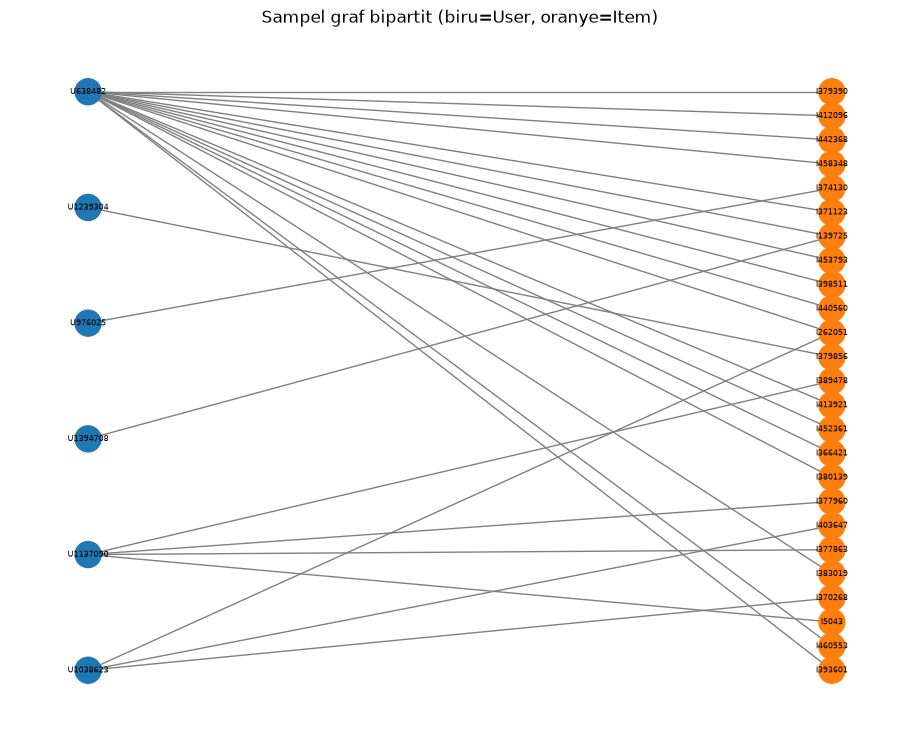

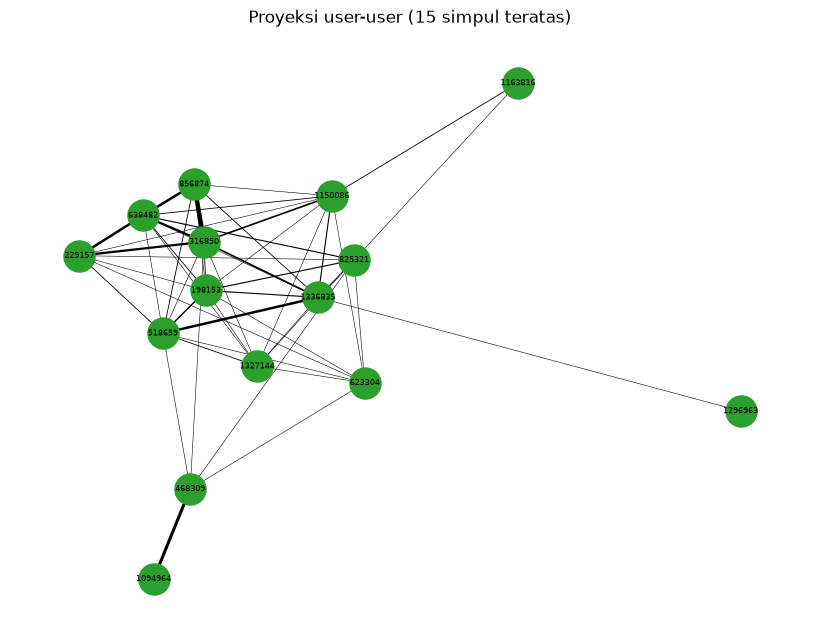

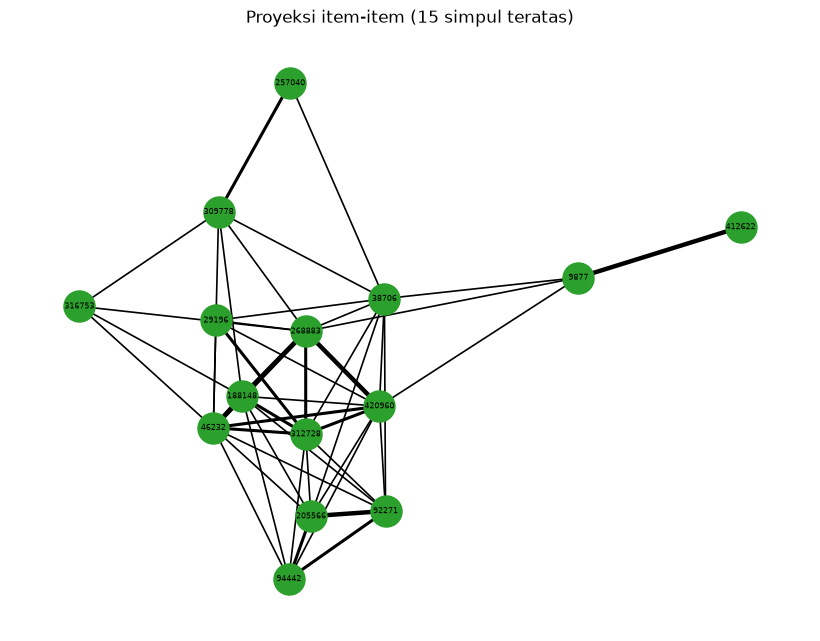

In [9]:
def plot_bipartite(M, n_users=10, n_items=25, seed=SEED):
    """Plot networkx sampel graf bipartit User-Item (bukan seluruh graf)."""
    rng = np.random.default_rng(seed)
    rows = rng.choice(M.shape[0], size=min(n_users, M.shape[0]), replace=False)
    sub = M[rows]
    top = np.argsort(-np.asarray((sub > 0).sum(0)).ravel())[:n_items]
    coo = sub[:, top].tocoo()
    U = [f"U{user_ids[r]}" for r in rows]; I = [f"I{item_ids[c]}" for c in top]
    G = nx.Graph(); G.add_nodes_from(U); G.add_nodes_from(I)
    for r, c, w in zip(coo.row, coo.col, coo.data): G.add_edge(U[r], I[c], weight=w)
    G.remove_nodes_from(list(nx.isolates(G)))
    left = [n for n in G if n.startswith("U")]
    pos = nx.bipartite_layout(G, left)
    colors = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G]
    plt.figure(figsize=(9, 7)); nx.draw(G, pos, with_labels=True, node_color=colors, node_size=350, font_size=6, edge_color="gray")
    plt.title("Sampel graf bipartit (biru=User, oranye=Item)"); plt.show()

def plot_projection(M, axis="user", n=15):
    """Plot proyeksi satu-mode dari n simpul berderajat tertinggi; bobot sisi = jumlah tetangga bersama."""
    X = M if axis == "user" else M.T.tocsr()
    ids = user_ids if axis == "user" else item_ids
    rows = np.argsort(-np.diff(X.indptr))[:n]
    B = (X[rows] > 0).astype(float)
    S = (B @ B.T).toarray(); np.fill_diagonal(S, 0)
    G = nx.Graph()
    for a in range(n):
        G.add_node(a)
        for b in range(a + 1, n):
            if S[a, b] > 0: G.add_edge(a, b, weight=S[a, b])
    w = [0.2 + 3 * G[a][b]["weight"] / S.max() for a, b in G.edges]
    plt.figure(figsize=(8, 6))
    nx.draw(G, nx.spring_layout(G, seed=SEED), labels={i: str(ids[r]) for i, r in enumerate(rows)},
            node_size=500, font_size=6, width=w, node_color="tab:green")
    plt.title(f"Proyeksi {axis}-{axis} ({n} simpul teratas)"); plt.show()

plot_bipartite(M)
plot_projection(M, "user")     # No. 4
plot_projection(M, "item")     # No. 5

**No. 4 — Karakteristik VSM User**

- **Dimensi dan shape:** Matriks VSM User berukuran (320, 3430). Ada 320 vektor user, dan tiap vektor hidup di ruang berdimensi 3.430, karena setiap dimensi mewakili satu item. Nilai tiap sel adalah total bobot interaksi user pada item tersebut (view=1, addtocart=3, buy=5).
- **Nilai tidak nol (nnz):** Hanya 3.948 sel yang terisi dari 1.097.600 sel (320 × 3.430), atau sekitar 0,36%.
- **Sparsity:** 99,64%. Hampir semua elemen vektor bernilai 0, karena satu user hanya berinteraksi dengan sebagian kecil dari seluruh item. Karena itu matriksnya disimpan sebagai sparse matrix (CSR).
- **Rata-rata nnz per vektor:** 12,34, artinya satu user rata-rata berinteraksi dengan sekitar 12 item berbeda. Jumlah ini cukup untuk membentuk vektor yang bisa dibandingkan dengan vektor user lain.
- **Memori:** 0,05 MB.
- **Plot bipartit (sampel 10 user, 25 item):** Biru adalah user dan oranye adalah item, dan sisi hanya menghubungkan user ke item. Distribusinya sangat timpang: user U638482 terhubung ke belasan item sekaligus, sedangkan user lain hanya terhubung ke 1–3 item. Sebagian besar item hanya dihubungkan satu user. Ini sesuai angka sparsity yang tinggi, dan juga menunjukkan ada user yang sangat aktif (heavy user) dan banyak user yang interaksinya sedikit.
- **Plot proyeksi user-user (15 user berderajat tertinggi):** Simpul adalah user, sisi berarti dua user berinteraksi dengan setidaknya satu item yang sama, dan ketebalan sisi menunjukkan jumlah item yang dipakai bersama. Terbentuk inti yang padat berisi sebagian besar simpul (misalnya 856874, 638482, 316850, 229157, 198153, 518659, 1336835) dengan banyak sisi di antaranya. Sisi paling tebal terlihat antara 856874 dan 316850, 638482 dan 229157, serta 518659 dan 1336835. Ada juga simpul di pinggir yang hanya terhubung lewat satu atau dua sisi tipis (1163816, 1296963) dan simpul 1094964 yang hanya terhubung ke 468309 lewat satu sisi tebal.

**No. 5 — Karakteristik VSM Item**

- **Dimensi dan shape:** Matriks VSM Item berukuran (3430, 320), yaitu transpose dari matriks user. Ada 3.430 vektor item, dan tiap vektor berdimensi 320 karena setiap dimensi mewakili satu user.
- **nnz dan sparsity:** Sama dengan VSM User, yaitu 3.948 dan 99,64%. Hal ini wajar karena keduanya berasal dari matriks yang sama, hanya dilihat dari sisi yang berbeda.
- **Rata-rata nnz per vektor:** 1,15. Satu item rata-rata hanya disentuh sekitar satu user, jadi sebagian besar vektor item hanya punya satu elemen tidak nol. Vektor seperti ini sulit dibandingkan karena hampir tidak beririsan dengan vektor item lain.
- **Memori:** 0,06 MB, sedikit lebih besar dari VSM User walaupun nnz sama. Penyebabnya, format CSR menyimpan satu pointer baris (`indptr`) per vektor, dan jumlah barisnya jauh lebih banyak (3.430 dibanding 320).
- **Plot proyeksi item-item (15 item berderajat tertinggi):** Simpul adalah item, sisi berarti kedua item pernah disentuh oleh user yang sama, dan ketebalan sisi menunjukkan jumlah user yang sama. Terlihat inti yang sangat padat (46232, 188148, 312728, 420960, 268883, 205566, 92271, 94442) dengan hampir semua pasangan saling terhubung. Sisi paling tebal ada pada pasangan seperti 188148–268883, 268883–420960, dan 205566–92271. Di pinggir ada pasangan terpencil 9877–412622 dan 257040–309778 yang tersambung lewat sisi tebal ke bagian lain.

**Notes:** Kedua plot proyeksi hanya memuat 15 simpul dengan derajat tertinggi, sehingga tampak jauh lebih padat daripada rata-rata seluruh graf. Ketebalan sisi juga dinormalkan terhadap sisi terbesar di masing-masing plot, jadi ketebalan antar-plot tidak bisa dibandingkan langsung.

### No. 6 — Proyeksi mana yang lebih baik?
Bandingkan secara kuantitatif: jumlah vektor (ukuran matriks similarity = n²), dimensi, sparsity, dan perkiraan jumlah sisi proyeksi (pasangan yang berbagi tetangga).

In [10]:
B = (M > 0).astype(float)
user_deg = np.asarray(B.sum(1)).ravel(); item_deg = np.asarray(B.sum(0)).ravel()

n_u, n_i = M.shape
cmp_ = pd.DataFrame({
    "Proyeksi User-User": {"jumlah simpul": n_u, "ukuran matriks sim (n^2)": n_u**2,
                           "perkiraan sisi (pasangan berbagi tetangga)": (item_deg*(item_deg-1)/2).sum()},
    "Proyeksi Item-Item": {"jumlah simpul": n_i, "ukuran matriks sim (n^2)": n_i**2,
                           "perkiraan sisi (pasangan berbagi tetangga)": (user_deg*(user_deg-1)/2).sum()},
})
display(cmp_.astype(int))

,Proyeksi User-User,Proyeksi Item-Item
jumlah simpul,320,3430
ukuran matriks sim (n^2),102400,11764900
perkiraan sisi (pasangan berbagi tetangga),705,110353


**No. 6 — Kesimpulan: proyeksi User-User lebih baik**

| | Proyeksi User-User | Proyeksi Item-Item |
|---|---|---|
| Jumlah simpul | 320 | 3.430 |
| Ukuran matriks similarity (n²) | 102.400 | 11.764.900 |
| Perkiraan sisi | 705 | 110.353 |
| Rata-rata nnz per vektor | 12,34 | 1,15 |

**1. Efisiensi :** Proyeksi User-User lebih efisien. Jumlah simpulnya hanya 320, sehingga matriks similarity-nya 102.400 sel, sekitar 115 kali lebih kecil daripada Item-Item (11.764.900 sel). Perkiraan sisinya juga jauh lebih sedikit, 705 dibanding 110.353 (sekitar 156 kali). Semakin kecil matriks dan jumlah sisi, semakin ringan komputasi cosine similarity dan penyimpanannya. Selisihnya akan makin besar kalau datanya diperbesar, karena ukuran matriks naik secara kuadrat terhadap jumlah simpul.

**2. Kepadatan dan informasi :** Proyeksi Item-Item memang punya lebih banyak sisi, tetapi banyak di antaranya semu. Sisi item-item terbentuk dari user yang berinteraksi dengan banyak item sekaligus: seorang user dengan n item menghasilkan n(n−1)/2 sisi. Kalau semua user sama aktifnya (rata-rata 12,34 item), perkiraan sisinya hanya sekitar 22.400, padahal hasil sebenarnya 110.353, kira-kira 5 kali lebih banyak. Berarti sisi-sisi itu didominasi oleh beberapa user yang sangat aktif (misalnya U638482 pada plot bipartit), dan item-item yang dilihat satu user "borongan" jadi tampak berhubungan padahal belum tentu mirip. Vektor item juga lemah secara informasi: rata-rata hanya 1,15 elemen tidak nol (satu item hanya disentuh sekitar satu user), sehingga cosine antar-item sulit dibandingkan. Sebaliknya, vektor user rata-rata terisi 12,34 elemen, jadi lebih informatif untuk dihitung kemiripannya.

**3. Kecocokan dengan tujuan :** Soal 2.2 meminta rekomendasi dengan KNN pada user (mencari k=5 tetangga terdekat dari seorang user). Itu langsung memakai similarity antar-user, jadi proyeksi User-User yang sesuai tanpa perlu konversi tambahan.

**Keterbatasan :** Perkiraan sisi User-User hanya 705, sedikit untuk 320 user. Artinya banyak user hanya berbagi sedikit item dengan user lain, sehingga ada user yang tetangganya punya cosine 0 atau bahkan tidak punya tetangga. Hal ini perlu diperhatikan saat memilih user acak untuk KNN di bagian Analytics. Selain itu, angka sisi dihitung dengan rumus n(n−1)/2 per simpul, sehingga pasangan yang berbagi lebih dari satu simpul dihitung berkali-kali (batas atas, bukan jumlah sisi unik).

**Keputusan:** Proyeksi User-User dipakai untuk no. 7 (similarity) dan 2.2 (KNN), yaitu `PROJ = "user"`.

### No. 7 — Similarity pada graf terproyeksi
Atur `PROJ` sesuai kesimpulan no. 6 (`"user"` atau `"item"`). Similarity = **cosine** pada vektor VSM.

In [11]:
PROJ = "user"
X, ids = (M, user_ids) if PROJ == "user" else (MT, item_ids)
label, key = ("Visitor", "visitorId") if PROJ == "user" else ("Item", "itemId")
Xn = normalize(X)    # L2-normalisasi -> dot product = cosine

def topk_sim(Xn, idx, k=5):
    s = (Xn @ Xn[idx].T).toarray().ravel()
    s[idx] = -1
    top = np.argpartition(-s, k)[:k]
    top = top[np.argsort(-s[top])]
    return top, s[top]

In [12]:
# hapus SIMILAR_TO lama (score 0, tidak bermakna)
run("MATCH ()-[r:SIMILAR_TO]->() DELETE r")

# hitung berapa tetangga (cosine > 0) tiap user
S = (Xn @ Xn.T).tocsr(); S.setdiag(0); S.eliminate_zeros()
n_pos = np.diff(S.indptr)
print("user punya >=1 tetangga:", int((n_pos >= 1).sum()), "| >=5 tetangga:", int((n_pos >= 5).sum()), "dari", X.shape[0])

# pilih acuan reproducible dari user yang punya >=5 tetangga (kalau tidak ada, turunkan ke >=1)
min_nb = 5 if (n_pos >= 5).any() else 1
cands = np.where(n_pos >= min_nb)[0]
ref_idx = int(np.random.default_rng(SEED).choice(cands))
ref_id = int(ids[ref_idx])

top, sims = topk_sim(Xn, ref_idx, 5)
mask = sims > 0
top, sims = top[mask], sims[mask]
print("Acuan:", label, ref_id, "| tetangga cosine > 0:", len(top))
display(pd.DataFrame({key: ids[top], "cosine": sims}))

user punya >=1 tetangga: 188 | >=5 tetangga: 58 dari 320
Acuan: Visitor 163049 | tetangga cosine > 0: 5


,visitorId,cosine
0,983447,0.578289
1,580290,0.145465
2,115677,0.102481
3,400676,0.088639
4,693709,0.030829


In [13]:
# STATE "SEBELUM": relasi milik node acuan + jumlah SIMILAR_TO di seluruh graf
before_rel = run(f"MATCH (a:{label} {{{key}: $ref}})-[r]-() RETURN type(r) AS relasi, count(*) AS n", ref=ref_id)
before_sim = run("MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS jumlah_SIMILAR_TO")
display(before_rel); display(before_sim)

# (b) tulis nilai similarity kembali ke graf
rows = [{"a": ref_id, "b": int(ids[j]), "score": float(s)} for j, s in zip(top, sims)]
_ = driver.execute_query(
        f"""UNWIND $rows AS row
        MATCH (a:{label} {{{key}: row.a}}), (b:{label} {{{key}: row.b}})
        MERGE (a)-[r:SIMILAR_TO]->(b)
        SET r.score = row.score, r.method = 'cosine'""", rows=rows, database_=DB)

,relasi,n
0,VIEWED,72
1,ADDED_TO_CART,1
2,BOUGHT,1


,jumlah_SIMILAR_TO
0,0


In [14]:
# (a) CYPHER: 5 record dengan similarity tertinggi untuk node acuan
q_top5 = f"""MATCH (a:{label} {{{key}: $ref}})-[s:SIMILAR_TO]->(b:{label})
RETURN b.{key} AS id, s.score AS similarity
ORDER BY similarity DESC LIMIT 5"""
print(q_top5)
display(run(q_top5, ref=ref_id))

MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor)
RETURN b.visitorId AS id, s.score AS similarity
ORDER BY similarity DESC LIMIT 5


,id,similarity
0,983447,0.578289
1,580290,0.145465
2,115677,0.102481
3,400676,0.088639
4,693709,0.030829


**No. 7 — Similarity pada graf terproyeksi (proyeksi User-User)**

**1. Cara menghitung :** Berdasarkan no. 6, proyeksi User-User yang dipakai. Tiap user direpresentasikan sebagai vektor berdimensi 3.430 (satu dimensi per item) dengan nilai bobot interaksi (view=1, addtocart=3, buy=5). Setiap vektor dinormalisasi L2 (`normalize`), sehingga perkalian dot antar-vektor sama dengan **cosine similarity**. Fungsi `topk_sim` menghitung cosine antara user acuan dan seluruh user lain, mengecualikan dirinya sendiri (`s[idx] = -1`), lalu mengambil 5 nilai tertinggi. Hanya tetangga dengan cosine > 0 yang disimpan (`sims > 0`), karena tetangga dengan cosine 0 tidak punya kemiripan sama sekali.

**2. Record acuan :** Visitor **163049**, dipilih acak dengan seed tetap (`SEED = 42`) dari user yang punya minimal 5 tetangga dengan cosine > 0. Pemilihan ini dilakukan setelah percobaan pertama memakai acuan lain (Visitor 118662) menghasilkan semua cosine = 0. Dari 320 user, hanya 188 (58,8%) yang punya minimal 1 tetangga dengan cosine > 0, dan hanya 58 (18,1%) yang punya minimal 5. Artinya, 132 user (41,3%) tidak punya tetangga sama sekali. Hal ini wajar untuk data yang sangat sparse: user jarang membuka item yang sama.

**3. Hasil 5 tetangga terdekat Visitor 163049 :**

| Peringkat | Visitor | Cosine |
|---|---|---|
| 1 | 983447 | 0,578 |
| 2 | 580290 | 0,145 |
| 3 | 115677 | 0,102 |
| 4 | 400676 | 0,089 |
| 5 | 693709 | 0,031 |

Hanya Visitor 983447 yang cukup mirip (cosine 0,578, atau sekitar 58% dari kemiripan maksimum), karena perilaku interaksinya banyak beririsan dengan acuan. Empat tetangga lainnya hanya berbagi sedikit item (cosine 0,03 sampai 0,15). Dalam konteks rekomendasi, tetangga dengan cosine rendah memberi sinyal yang lemah, jadi 983447 diperkirakan paling berpengaruh pada hasil KNN nanti.

**4. (b) Menulis similarity ke graf :** Nilai cosine ditulis sebagai relasi `SIMILAR_TO` dengan properti `score` dan `method = 'cosine'`. Cypher yang digunakan:

- `UNWIND $rows AS row` memecah daftar pasangan (acuan, tetangga, skor) menjadi baris yang diproses satu per satu.
- `MATCH (a:Visitor {visitorId: row.a}), (b:Visitor {visitorId: row.b})` mencari kedua simpul yang sudah ada di graf.
- `MERGE (a)-[r:SIMILAR_TO]->(b)` membuat relasi kalau belum ada. `MERGE` dipakai (bukan `CREATE`) supaya menjalankan ulang tidak membuat relasi ganda.
- `SET r.score = row.score, r.method = 'cosine'` menyimpan nilai similarity sebagai properti relasi.

Sebelum penulisan, jumlah relasi `SIMILAR_TO` di graf adalah 0. Setelahnya menjadi 5.

**5. (a) Cypher untuk 5 record dengan similarity tertinggi :**

```cypher
MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor)
RETURN b.visitorId AS id, s.score AS similarity
ORDER BY similarity DESC LIMIT 5
```

`MATCH` mencari relasi `SIMILAR_TO` yang keluar dari acuan, `RETURN` mengambil ID tetangga dan skornya, `ORDER BY ... DESC` mengurutkan dari similarity terbesar, dan `LIMIT 5` membatasi 5 hasil. Query ini dijalankan setelah (b) karena membaca nilai yang sudah tersimpan di graf. Hasilnya identik dengan perhitungan di Python (tabel pada poin 3), sehingga penulisan ke graf terbukti benar.

**6. Keterbatasan.** (i) Similarity hanya dihitung untuk satu acuan, belum untuk seluruh user. (ii) Karena data sangat sparse, sebagian user tidak punya tetangga atau tetangganya lemah, sehingga rekomendasi berbasis KNN akan tidak stabil untuk user seperti itu. (iii) Cosine pada bobot interaksi menganggap view, addtocart, dan buy berbeda hanya lewat besarnya bobot, bukan lewat makna perilakunya.

### No. 8 — Kondisi sebelum vs sesudah similarity

**Sebelum** (tanpa SIMILAR_TO):
```cypher
MATCH p=(a:Visitor {visitorId: 163049})-[r]-(b) WHERE type(r) <> 'SIMILAR_TO' RETURN p
```
![Sebelum](visualisasi/no.8_sebelum.png)

**Sesudah** (dengan SIMILAR_TO):
```cypher
MATCH p=(a:Visitor {visitorId: 163049})-[:SIMILAR_TO]->(b) RETURN p
```
![Sesudah](visualisasi/no.8_sesudah.png)

SEBELUM:


,relasi,n
0,VIEWED,72
1,ADDED_TO_CART,1
2,BOUGHT,1


SESUDAH:


,relasi,n
0,VIEWED,72
1,ADDED_TO_CART,1
2,BOUGHT,1
3,SIMILAR_TO,5


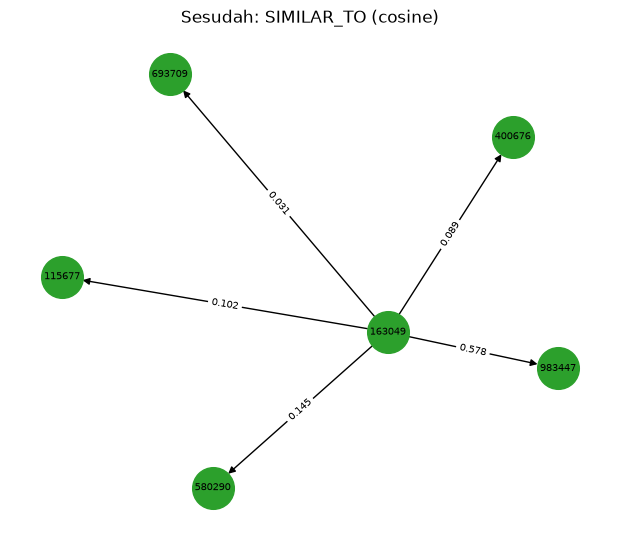

In [15]:

after_rel = run(f"MATCH (a:{label} {{{key}: $ref}})-[r]-() RETURN type(r) AS relasi, count(*) AS n", ref=ref_id)
print("SEBELUM:"); display(before_rel); print("SESUDAH:"); display(after_rel)

G = nx.DiGraph()
for _, r in run(q_top5, ref=ref_id).iterrows():
    G.add_edge(f"{ref_id}", f"{int(r['id'])}", weight=round(r["similarity"], 3))
pos = nx.spring_layout(G, seed=SEED)
plt.figure(figsize=(6, 5)); nx.draw(G, pos, with_labels=True, node_size=900, font_size=7, node_color="tab:green")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=7)
plt.title("Sesudah: SIMILAR_TO (cosine)"); plt.show()

**No. 8 — Kondisi sebelum vs sesudah perhitungan similarity**

Record acuan: Visitor 163049 (proyeksi User-User, cosine similarity pada VSM).

| Jenis relasi milik Visitor 163049 | Sebelum | Sesudah |
|---|---|---|
| VIEWED | 72 | 72 |
| ADDED_TO_CART | 1 | 1 |
| BOUGHT | 1 | 1 |
| SIMILAR_TO | 0 | 5 |
| **Total** | **74** | **79** |

1. **Perubahan pada graf.** Sebelum similarity dihitung, Visitor 163049 hanya terhubung ke item lewat tiga jenis relasi interaksi (74 relasi). Sesudahnya muncul 5 relasi baru bertipe `SIMILAR_TO` yang menghubungkan visitor ini ke 5 visitor lain. Relasi lama tidak berubah (72, 1, dan 1), jadi proses ini hanya menambah informasi tanpa merusak data asli.
2. **Jenis relasi baru.** Relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` menghubungkan Visitor ke Item (bipartit). Relasi `SIMILAR_TO` menghubungkan Visitor ke Visitor, sehingga graf kini punya lapisan hubungan antar-user yang diturunkan dari proyeksi User-User. Nilainya disimpan sebagai properti `score` (dengan `method = cosine`).
3. **Nilai similarity pada plot networkx.** Visitor 163049 menjadi pusat bintang dengan 5 tetangga:
   - 983447 (0,578): paling mirip, satu-satunya yang kemiripannya sedang.
   - 580290 (0,145), 115677 (0,102), 400676 (0,089), 693709 (0,031): kemiripannya rendah.
4. **Makna angkanya.** Cosine di antara 0 dan 1 (semua nilai matriks tidak negatif). Kecuali 983447, kelima tetangga hanya berbagi sedikit item dengan visitor acuan. Hal ini sesuai karakter data yang sangat sparse (sparsity 99,64%), di mana user jarang membuka item yang sama. Jadi hanya 983447 yang layak dianggap tetangga dekat, sedangkan sisanya sekadar tetangga terdekat yang tersedia.
5. **Arah relasi.** Relasi disimpan berarah dari acuan ke tetangga (163049 → tetangga), walaupun cosine sendiri simetris. Karena itu query yang mencari tetangga dari 163049 memakai arah `->`.
6. **Manfaat.** Relasi `SIMILAR_TO` bisa langsung dibaca lewat Cypher tanpa menghitung ulang di Python, dan menjadi dasar KNN pada bagian Analytics: tetangga terdekat user menjadi sumber rekomendasi item.

## 2.2 Analytics

### No. 1 — Pilih user acak (reproducible) & rekomendasi KNN
- Proses acak: `np.random.default_rng(SEED)` memilih dari user yang punya *ground truth* di P2 (item yang di-*addtocart*/*transaction*, dan item itu ada di katalog P1).
- KNN: k=5 tetangga terdekat (cosine pada VSM user). Skor item = Σ (similarity tetangga × bobot interaksi tetangga), item yang sudah pernah disentuh user dibuang.
- Dihasilkan 5 item terurut untuk evaluasi @5; **3 teratas = item yang "diiklankan"**.

In [16]:
K, N_REC, N_AD = 5, 5, 3
GT_EVENTS = {"addtocart", "transaction"}

test = pd.read_csv(f"{DATA_DIR}/events_P2_test.csv")
gt_all = test[test["event"].isin(GT_EVENTS)].groupby("visitorid")["itemid"].apply(set).to_dict()
item_set = set(item_ids.tolist())
user_index = {int(u): i for i, u in enumerate(user_ids)}
gt = {u: g & item_set for u, g in gt_all.items() if u in user_index}
gt = {u: g for u, g in gt.items() if g}
eligible = sorted(gt)
print("user eligible:", len(eligible))

Mn = normalize(M)

def recommend_knn(uidx, k=K, n_rec=N_REC):
    nb, sims = topk_sim(Mn, uidx, k)
    scores = np.asarray(M[nb].T @ sims).ravel()
    scores[M[uidx].indices] = -np.inf
    order = np.argsort(-scores)[:n_rec]
    order = order[scores[order] > 0]
    return nb, sims, [int(item_ids[j]) for j in order]

target = int(np.random.default_rng(SEED).choice(eligible))
nb, sims, rec = recommend_knn(user_index[target])
print("User terpilih:", target)
print("KNN (k=5):"); display(pd.DataFrame({"visitorId": user_ids[nb], "cosine": sims}))
print("Top-5 rekomendasi:", rec)
print("3 item yang diiklankan:", rec[:N_AD])
print("Ground truth (P2):", gt[target])

user eligible: 12
User terpilih: 518659
KNN (k=5):


,visitorId,cosine
0,1065157,0.163236
1,824842,0.141605
2,266291,0.130710
3,649511,0.115711
4,1336835,0.103625


Top-5 rekomendasi: [133907, 147684, 444365, 344723, 61303]
3 item yang diiklankan: [133907, 147684, 444365]
Ground truth (P2): {104275}


**No. 1 — Pemilihan user acak dan rekomendasi KNN**

**1. Pemilihan user acak (reproducible) :** Dari 320 user di graf, hanya **12 user** yang memenuhi syarat (eligible), yaitu user yang di periode test (P2) melakukan `addtocart` atau `transaction` pada item yang ada di katalog P1, sehingga punya ground truth untuk dievaluasi. User dipilih dengan `np.random.default_rng(SEED).choice(eligible)` dengan `SEED = 42`, jadi hasilnya sama setiap kali dijalankan. User terpilih: **Visitor 518659**.

**2. Cara kerja KNN (k = 5) :** Pertama, cosine similarity dihitung antara vektor user 518659 dan vektor semua user lain (VSM User, ternormalisasi L2), lalu 5 user dengan cosine tertinggi diambil sebagai tetangga. Kedua, skor tiap item dihitung sebagai jumlah (similarity tetangga × bobot interaksi tetangga pada item itu), sehingga item yang dipakai tetangga yang lebih mirip, dan dengan interaksi yang lebih kuat (misalnya beli), mendapat skor lebih tinggi. Ketiga, item yang sudah pernah disentuh user 518659 dibuang (`scores[M[uidx].indices] = -inf`), jadi yang direkomendasikan hanya item baru. Keempat, item diurutkan menurut skor, dan 5 teratas dipakai untuk evaluasi @5.

**3. Hasil tetangga terdekat :**

| Peringkat | Visitor | Cosine |
|---|---|---|
| 1 | 1065157 | 0,163 |
| 2 | 824842 | 0,142 |
| 3 | 266291 | 0,131 |
| 4 | 649511 | 0,116 |
| 5 | 1336835 | 0,104 |

Semua tetangga punya cosine rendah (0,10 sampai 0,16) dan selisih antar-peringkat kecil, jadi tidak ada satu tetangga yang menonjol. Kemiripannya lemah karena data sangat sparse (99,64%), sehingga user jarang membuka item yang sama. Tetangga ini adalah yang "paling mirip yang tersedia", belum tentu benar-benar mirip.

**4. Hasil rekomendasi :**
Soal meminta 3 item yang diiklankan, sedangkan metrik dihitung @5. Karena itu rekomendasi dihasilkan sebanyak 5 item terurut untuk evaluasi, dan 3 item teratas ditampilkan sebagai item iklan.
- Top-5 rekomendasi: 133907, 147684, 444365, 344723, 61303.
- **3 item yang diiklankan** (k = 5): **133907, 147684, 444365**.
- Ground truth di P2: {104275}.

**5. Pengamatan :** Item ground truth (104275) **tidak termasuk** dalam 5 item rekomendasi, jadi pada kasus ini rekomendasi belum tepat sasaran. Penyebab yang masuk akal: (i) ground truth hanya 1 item, sehingga peluang cocok sangat kecil di antara ribuan item; (ii) tetangga lemah (cosine ≤ 0,16) sehingga sinyal rekomendasinya tidak kuat; (iii) item itu terbukti tidak pernah disentuh kelima tetangga, sehingga tidak mungkin muncul di skor KNN; (iv) jarak waktu P1 (Juni) dan P2 (akhir Agustus) sekitar 2 bulan, sehingga minat user bisa berubah.

**6. Keterbatasan :** Hasil ini berasal dari satu user saja, sehingga tidak mewakili kualitas model secara umum. Jumlah user eligible hanya 12, jadi evaluasi menyeluruh juga terbatas. Hit@5 dan NDCG@5 dihitung pada soal no. 2.

### No. 2 — Hit@5 dan NDCG@5
- **Hit@5** = 1 jika ≥ 1 item relevan ada di 5 teratas, selain itu 0.
- **NDCG@5** = DCG / IDCG, DCG = Σ rel_i / log2(i+1) (i mulai dari 1); IDCG = DCG urutan ideal.

In [17]:
def hit_at_k(rec, rel, k=5):
    return int(any(i in rel for i in rec[:k]))

def ndcg_at_k(rec, rel, k=5):
    dcg  = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:k]) if i in rel)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), k)))
    return dcg / idcg if idcg else 0.0

print(f"Hit@5  (user {target}) = {hit_at_k(rec, gt[target])}")
print(f"NDCG@5 (user {target}) = {ndcg_at_k(rec, gt[target]):.4f}")

Hit@5  (user 518659) = 0
NDCG@5 (user 518659) = 0.0000


In [18]:
sample = np.random.default_rng(SEED).choice(eligible, size=min(200, len(eligible)), replace=False)
H, N = [], []
for u in sample:
    _, _, r = recommend_knn(user_index[int(u)])
    H.append(hit_at_k(r, gt[int(u)])); N.append(ndcg_at_k(r, gt[int(u)]))
print(f"Rata-rata ({len(sample)} user): Hit@5 = {np.mean(H):.4f} | NDCG@5 = {np.mean(N):.4f}")

Rata-rata (12 user): Hit@5 = 0.0833 | NDCG@5 = 0.0168


**No. 2 — Hit@5 dan NDCG@5**

**1. Hasil untuk user terpilih (Visitor 518659)**

| Metrik | Nilai |
|---|---|
| Hit@5 | 0 |
| NDCG@5 | 0,0000 |

**Apakah hit?** Tidak. Item ground truth di P2 hanya satu, yaitu 104275, sedangkan 5 item rekomendasi adalah 133907, 147684, 444365, 344723, dan 61303. Item 104275 tidak ada di antaranya, jadi Hit@5 = 0. Karena tidak ada item relevan di 5 teratas, **tidak ada peringkat hit**. NDCG@5 ikut 0 karena DCG = 0 (tidak ada item relevan yang memberi kontribusi), sehingga DCG/IDCG = 0.

**2. Hasil rata-rata pada seluruh user eligible.** Karena user eligible hanya 12 (bukan 200), semuanya ikut dievaluasi.

| Metrik | Nilai |
|---|---|
| Hit@5 rata-rata | 0,0833 (1 dari 12 user) |
| NDCG@5 rata-rata | 0,0168 |

Hanya satu dari 12 user yang mendapat hit, yaitu Visitor 1126569, dengan item relevan pertama pada **peringkat ke-4** dari 3 item ground truth (NDCG@5 = 0,2021). Ke-11 user lainnya tidak mendapat hit sama sekali (Hit@5 = 0 dan NDCG@5 = 0), termasuk user 530559 yang punya 19 item ground truth.

**3. Mengapa nilainya rendah?**

1. **Data sangat sparse (sparsity 99,64%) :** User jarang membuka item yang sama, sehingga tetangga KNN hanya mirip secara lemah. Untuk user 518659, kelima tetangga punya cosine hanya 0,10 sampai 0,16. Sinyal yang lemah menghasilkan rekomendasi yang kurang akurat.
2. **Ruang pencarian besar :** Ada 3.430 item di katalog, sedangkan hanya 5 yang direkomendasikan dan ground truth rata-rata hanya satu atau beberapa item. Dengan tebakan acak, peluang hit per user sangat kecil, karena hanya 5 dari 3.430 item yang direkomendasikan. Hit@5 rata-rata sebesar 8,3% (1 dari 12 user) memang di atas tebakan acak, tetapi dengan jumlah user sekecil ini belum cukup untuk menyimpulkan bahwa model menangkap sinyal.
3. **Item ground truth mungkin tidak pernah disentuh tetangga :** KNN hanya bisa merekomendasikan item yang pernah dipakai tetangganya. Kalau item di P2 tidak ada di antara item tetangga, ia tidak mungkin muncul di rekomendasi.
4. **Jarak waktu P1 ke P2 :** P1 (1–15 Juni) dan P2 (16–31 Agustus) berjarak sekitar 2 bulan, sehingga minat user bisa berubah. Item yang dibeli di P2 belum tentu mirip dengan item di P1.
5. **Item yang sudah dikenal dibuang :** Item yang sudah disentuh user di P1 tidak direkomendasikan lagi. Kalau user di P2 menambahkan ke keranjang item yang sama dengan yang ia lihat di P1, item itu tidak mungkin menjadi hit.

**4. Keterbatasan**

- **Data jarang (sparse) :** dijelaskan di atas. Hanya 188 dari 320 user (58,8%) punya minimal satu tetangga dengan cosine > 0, dan hanya 58 user (18,1%) punya minimal 5. Banyak user tidak bisa dibuatkan rekomendasi yang bermakna.
- **Cold-start :** (a) *user baru* yang tidak ada di P1 tidak punya vektor, jadi tidak bisa mendapat rekomendasi; (b) *user dengan sedikit interaksi* hampir tidak punya tetangga; (c) *item baru* yang tidak ada di katalog P1 tidak pernah bisa direkomendasikan, karena itu ground truth dibatasi pada item yang ada di katalog P1.
- **Hanya 1 user (dan hanya 12 user untuk rata-rata) :** Hit@5 untuk satu user hanya bernilai 0 atau 1, jadi sangat tidak stabil. Pada rata-rata 12 user, perubahan satu user saja mengubah Hit@5 sebesar 8,3 poin persentase. Karena itu angka ini tidak cukup untuk menyimpulkan kualitas model secara umum.
- **Definisi ground truth :** item relevan didefinisikan sebagai item yang di-`addtocart` atau `transaction` di P2 (bukan `view`), dan harus ada di katalog P1. Definisi yang ketat ini membuat jumlah item relevan sedikit, dan user eligible hanya 12. Kalau `view` ikut dihitung relevan, ground truth lebih banyak dan Hit@5 cenderung naik, tetapi maknanya lebih longgar (melihat belum tentu berminat).
- **Evaluasi tanpa pembanding :** belum ada baseline sebagai pembanding, misalnya merekomendasikan 5 item paling populer. Tanpa itu, sulit menilai apakah KNN benar-benar lebih baik daripada pendekatan sederhana.
- **Pengaturan model :** bobot interaksi (1/3/5) dan k = 5 ditentukan tanpa tuning.
- **Bias seleksi user :** 320 user di graf dipilih dengan melihat bahwa mereka juga aktif di P2. Cara ini diperlukan agar ada ground truth untuk evaluasi, tetapi hasilnya hanya berlaku untuk user yang kembali bertransaksi, bukan untuk semua pengunjung.

**5. Kesimpulan :** Pada user 518659, rekomendasi KNN tidak mengenai item ground truth (Hit@5 = 0, NDCG@5 = 0). Secara rata-rata pada 12 user, Hit@5 = 0,0833 dan NDCG@5 = 0,0168. Nilainya rendah terutama karena data sangat sparse, tetangga lemah, dan ground truth sedikit. Hasil ini hanya indikatif, dan perbaikannya perlu data yang lebih padat atau periode yang lebih panjang.

In [19]:
rows = []
for u in eligible:
    _, _, r = recommend_knn(user_index[u]); g = gt[u]
    rank = next((i + 1 for i, x in enumerate(r) if x in g), None)
    rows.append({"user": u, "jumlah_GT": len(g), "Hit@5": hit_at_k(r, g),
                 "NDCG@5": round(ndcg_at_k(r, g), 4), "peringkat_hit": rank})
tabel = pd.DataFrame(rows)

tampil = tabel.copy()
tampil["peringkat_hit"] = [("-" if pd.isna(x) else int(x)) for x in tabel["peringkat_hit"]]
display(tampil)
print("rata-rata Hit@5:", round(tabel["Hit@5"].mean(), 4), "| rata-rata NDCG@5:", round(tabel["NDCG@5"].mean(), 4))

,user,jumlah_GT,Hit@5,NDCG@5,peringkat_hit
0,198153,2,0,0.0000,-
1,518659,1,0,0.0000,-
2,530559,19,0,0.0000,-
3,588140,1,0,0.0000,-
4,824842,3,0,0.0000,-
5,895999,3,0,0.0000,-
6,899857,4,0,0.0000,-
7,1126569,3,1,0.2021,4
8,1150086,8,0,0.0000,-
9,1165148,1,0,0.0000,-


rata-rata Hit@5: 0.0833 | rata-rata NDCG@5: 0.0168


**Interpretasi tabel Hit@5 dan NDCG@5 per user**

Dari 12 user eligible, hanya **satu user yang mendapat hit**, yaitu Visitor 1126569. Item relevan pertamanya muncul di **peringkat ke-4** dari 3 item ground truth miliknya, sehingga Hit@5 = 1 dan NDCG@5 = 0,2021. Nilai ini bisa diperiksa dengan rumus: DCG = 1/log₂(4+1) = 0,4307 dan IDCG = 1 + 1/log₂3 + 1/log₂4 = 2,1309, sehingga NDCG = 0,4307 / 2,1309 = 0,2021. NDCG kecil walaupun terjadi hit karena item relevan berada di peringkat bawah dan hanya 1 dari 3 item relevan yang berhasil ditemukan.

Sebelas user lainnya tidak mendapat hit (Hit@5 = 0 dan NDCG@5 = 0), termasuk user 530559 yang punya 19 item ground truth dan user 1150086 dengan 8 item. Jadi banyaknya item relevan tidak menjamin hit. Rata-rata keseluruhan Hit@5 = 1/12 = 0,0833 dan NDCG@5 = 0,2021/12 = 0,0168, sama persis dengan hasil sel sebelumnya. Hasil ini menunjukkan model hanya berhasil pada 1 dari 12 user, tetapi jumlah user terlalu kecil untuk menyimpulkan kualitas model secara umum.

In [20]:
uidx = user_index[target]
nb_idx, _, _ = recommend_knn(uidx)
item_gt = list(gt[target])[0]
j = int(np.where(item_ids == item_gt)[0][0])
print("item", item_gt, "disentuh tetangga:", [int(user_ids[n]) for n in nb_idx if M[n, j] > 0])

item 104275 disentuh tetangga: []


**Interpretasi pengecekan item ground truth user 518659**

Daftar tetangga yang pernah menyentuh item 104275 **kosong**, artinya tidak ada satu pun dari 5 tetangga KNN yang pernah berinteraksi dengan item tersebut di P1. Ini membuktikan dugaan (iii) pada bagian pengamatan: karena skor item pada KNN dihitung dari interaksi tetangga, item yang tidak pernah disentuh tetangga memiliki skor 0 dan **tidak mungkin muncul** di rekomendasi, sebesar apa pun peringkat 5 item teratas lainnya. Jadi kegagalan pada user 518659 bukan karena kebetulan urutan, melainkan keterbatasan pendekatan KNN berbasis user ini: hanya bisa merekomendasikan item yang sudah dikenal oleh tetangganya.